# Frozen Lake — tabular Q-learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/racousin/data_science_practice/blob/main/website/public/modules/ms2a-machine-learning-practice/challenges/mlp-s9-frozenlake-q-learning.ipynb)

**MS2A — Machine Learning Practice · Session 9, Reinforcement Learning**

The agent does not know the map nor the dynamics of the lake: it learns a table
$Q(s, a)$ from its own episodes, then acts greedily on it. The table you obtain on the
slippery 8x8 lake is your submission to
[challenge 202](https://ml-arena.com/viewchallenge/202), scored by the **success rate over
100 episodes**.

| Section | What you do |
|---|---|
| 1 | Look at the environment: states, actions, reward |
| 2 | Evaluate fixed policies: the baselines to beat |
| 3 | Write the ε-greedy policy and the Q-learning update |
| 4 | Train on the 4x4 lake |
| 5 | Decay ε: from exploration to exploitation |
| 6 | Train on the 8x8 lake |
| 7 | Write `agent.py`, submit, read the leaderboard |

Target: beat the benchmark (always move right, ≈ 0.25) and reach ≈ 0.6.

## 0. Setup

In [25]:
!pip install -q "gymnasium==1.3.0" "mlarena-sdk>=4.6"
from google.colab import userdata

import mlarena
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

API_TOKEN = userdata.get('api_key_mlarena')   # <-- paste your token (Profile page)
CHALLENGE_ID = 202

client = mlarena.connect(api_key=API_TOKEN, base_url="https://ml-arena.com")
rng = np.random.default_rng(0)

## 1. The environment

The lake is a grid: **S** start, **F** frozen (safe), **H** hole (the episode ends with
reward 0), **G** goal (the episode ends with reward 1). A state is the cell index
`row * ncol + col`; an action is 0 left, 1 down, 2 right, 3 up. By default the ice is
**slippery**: the agent moves in the intended direction with probability 1/3, and in each
of the two perpendicular directions with probability 1/3.

In [26]:
env4 = gym.make("FrozenLake-v1", map_name="4x4")
env8 = gym.make("FrozenLake-v1", map_name="8x8")

print(env4.unwrapped.desc.astype(str))
print("states:", env4.observation_space, "| actions:", env4.action_space)

[['S' 'F' 'F' 'F']
 ['F' 'H' 'F' 'H']
 ['F' 'F' 'F' 'H']
 ['H' 'F' 'F' 'G']]
states: Discrete(16) | actions: Discrete(4)


The model is exposed in `env.unwrapped.P[s][a]`: a list of `(probability, next_state,
reward, terminated)`. The agent will **not** use it; we read it once to see the slip.

In [27]:
for p, s2, r, done in env4.unwrapped.P[0][2]:   # state 0, action "right"
    print(f"p={p:.2f} -> state {s2}, reward {r}, terminated {done}")

p=0.33 -> state 4, reward 0, terminated False
p=0.33 -> state 1, reward 0, terminated False
p=0.33 -> state 0, reward 0, terminated False


**Questions**
- How many states and actions does each lake have? How many entries does a Q-table hold for
  the 8x8 lake?
- The reward is 1 at the goal and 0 everywhere else. What does $Q(s, a)$ equal for every
  pair until the agent has reached the goal once? What does that imply for an agent that
  never explores?
- Is the transition model deterministic? What does the slip change about the best path
  along a row of holes?

## 2. Evaluate a policy

A deterministic policy is a table `policy[s] -> a`. `evaluate` plays it greedily on
seeded episodes and returns the success rate: the score the leaderboard computes, over
more episodes.

In [28]:
def evaluate(env, policy, n=1000, seed=0):
    """Success rate of a deterministic policy (array of one action per state)."""
    wins = 0.0
    for i in range(n):
        s, _ = env.reset(seed=seed + i)
        done = False
        while not done:
            s, r, terminated, truncated, _ = env.step(int(policy[s]))
            wins += r
            done = terminated or truncated
    return wins / n

for name, env in [("4x4", env4), ("8x8", env8)]:
    n_s = env.observation_space.n
    print(name, "random:", evaluate(env, rng.integers(0, 4, n_s)),
          "| always right:", evaluate(env, np.full(n_s, 2)))

4x4 random: 0.024 | always right: 0.024
8x8 random: 0.001 | always right: 0.234


**Questions**
- The leaderboard scores 100 episodes. If the true success rate is $p = 0.6$, what is the
  standard deviation of the score, $\sqrt{p(1-p)/100}$? Is a difference of 0.03 between
  two submissions meaningful?
- Why do we evaluate on a fixed list of seeds?

## 3. Q-learning

Q-learning estimates the optimal action value $Q^*(s, a)$ from transitions
$(S_t, A_t, R_{t+1}, S_{t+1})$, with no model of the environment:

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha \big(R_{t+1} + \gamma \max_a Q(S_{t+1},a) - Q(S_t,A_t)\big)$$

The term in parentheses is the **TD error**. When $S_{t+1}$ is terminal its value is 0, so
the target is $R_{t+1}$ alone.

It is **off-policy**: the agent learns the greedy policy while it behaves
**ε-greedily**: with probability ε a random action (explore), otherwise the action of
highest $Q$ (exploit).

**Exercise 1.** Write the ε-greedy choice. When several actions share the maximum (at
the start, all of them), pick one at random among them.

In [39]:
def epsilon_greedy(q_s, epsilon):
    """q_s: the 4 action values of one state. Returns an action index."""
    if rng.random() < epsilon:
        return int(rng.integers(len(q_s))) # TODO: a random action
    return int(rng.choice(np.flatnonzero(q_s == q_s.max()))) # TODO: an action of maximal value, ties broken at random

**Exercise 2.** Complete the agent: a Q-table of zeros of shape `(n_states, n_actions)`
and the update above in `train`. `done` is `terminated` (a hole or the goal), not
`truncated`: an episode cut after 200 steps does not end in a state of value 0.

In [40]:
class QAgent:
    def __init__(self, env, gamma=0.99, alpha=0.1, epsilon=0.1):
        self.gamma, self.alpha, self.epsilon = gamma, alpha, epsilon
        self.q = np.zeros((env.observation_space.n, env.action_space.n)) # TODO: the Q-table

    def act(self, s):
        return epsilon_greedy(self.q[s], self.epsilon)

    def train(self, s, a, r, s2, done):
        if done:
          target = r  # TODO: r + gamma * max_a Q(s2, a), or r if done
        else:
          target = r + self.gamma * self.q[s2].max()
        td_error = target - self.q[s,a]  # TODO
        self.q[s, a] +=  self.alpha * td_error # TODO

    def end_episode(self):
        pass

The training loop is given: one call to `train` per step, one to `end_episode` per episode.

In [41]:
def run_training(env, agent, n_episodes):
    rewards = np.zeros(n_episodes)
    for i in range(n_episodes):
        s, _ = env.reset()
        done = False
        while not done:
            a = agent.act(s)
            s2, r, terminated, truncated, _ = env.step(a)
            agent.train(s, a, r, s2, terminated)
            s, done = s2, terminated or truncated
            rewards[i] += r
        agent.end_episode()
    return rewards

def plot_rewards(rewards_by_name, window=100):
    for name, rewards in rewards_by_name.items():
        plt.plot(np.convolve(rewards, np.ones(window) / window, mode="valid"), label=name)
    plt.xlabel("episode"); plt.ylabel(f"success rate (moving average, {window})")
    plt.legend(); plt.show()

## 4. Train on the 4x4 lake

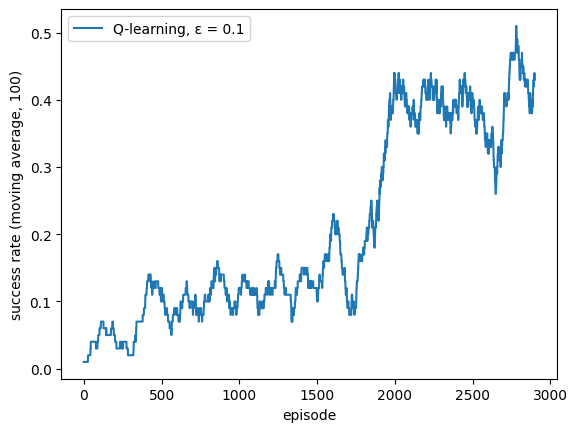

greedy success rate: 0.741


In [42]:
agent4 = QAgent(env4, epsilon=0.1)
rewards4 = run_training(env4, agent4, 3000)
plot_rewards({"Q-learning, ε = 0.1": rewards4})
print("greedy success rate:", evaluate(env4, agent4.q.argmax(axis=1)))

**Questions**
- The training curve and the greedy evaluation measure two different policies. Which ones?
  Why is the greedy success rate higher?
- Print `agent4.q.argmax(axis=1).reshape(4, 4)`. Next to a hole, does the greedy action
  point toward the goal or away from the hole? Why, on slippery ice?
- Set `epsilon=0` and train again. What happens, and how does it relate to the sparse
  reward of Section 1?

## 5. From exploration to exploitation

A constant ε keeps exploring at the end, when $Q$ is already good. A common schedule
starts at ε = 1 (pure exploration) and multiplies ε by a factor after each episode, down
to a floor:

$$\varepsilon_{k+1} = \max(\varepsilon_{\min},\ \lambda\, \varepsilon_k)$$

**Exercise 3.** Write `end_episode` in `DecayAgent`.

In [43]:
class DecayAgent(QAgent):
    def __init__(self, env, decay=0.999, epsilon_min=0.05, **kwargs):
        super().__init__(env, epsilon=1.0, **kwargs)
        self.decay, self.epsilon_min = decay, epsilon_min

    def end_episode(self):
        self.epsilon = max(self.epsilon_min, self.decay * self.epsilon) # TODO: epsilon <- max(epsilon_min, decay * epsilon)

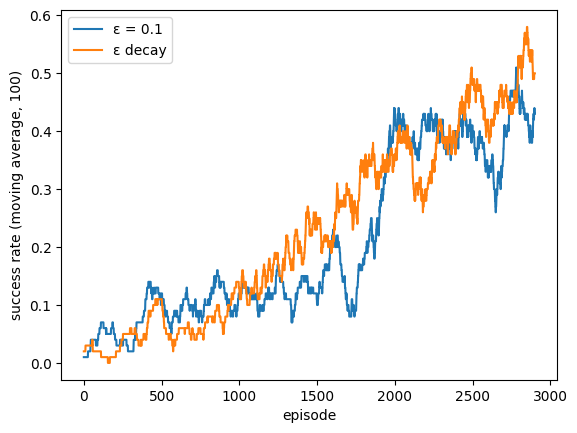

greedy success rate: 0.547


In [44]:
decay4 = DecayAgent(env4)
plot_rewards({"ε = 0.1": rewards4, "ε decay": run_training(env4, decay4, 3000)})
print("greedy success rate:", evaluate(env4, decay4.q.argmax(axis=1)))

**Questions**
- After how many episodes does ε reach its floor with `decay=0.999`? With `0.9999`?
- Why does the decaying agent's training curve start lower and end higher?

## 6. The 8x8 lake

Same code, 64 states, a goal 14 moves away at best, and many more holes. The goal is now
rarely reached by chance, so ε decays more slowly (`0.9995`) over more episodes (10,000,
about a minute).

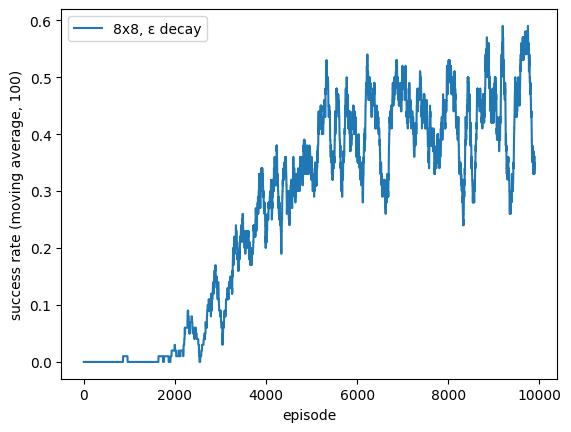

greedy success rate: 0.559
[['↓' '→' '→' '→' '→' '→' '→' '↑']
 ['↑' '↑' '↑' '↑' '↑' '→' '→' '↓']
 ['→' '→' '←' '←' '→' '↑' '→' '↓']
 ['↑' '↑' '←' '↑' '←' '←' '→' '→']
 ['↑' '↑' '←' '←' '→' '↓' '↑' '→']
 ['→' '←' '←' '↓' '↑' '←' '←' '→']
 ['↑' '←' '←' '→' '←' '←' '←' '→']
 ['←' '←' '←' '←' '↓' '←' '↓' '←']]


In [45]:
agent8 = DecayAgent(env8, decay=0.9995)
rewards8 = run_training(env8, agent8, 10000)
plot_rewards({"8x8, ε decay": rewards8})
policy8 = agent8.q.argmax(axis=1)
print("greedy success rate:", evaluate(env8, policy8))
print(np.array(list("←↓→↑"))[policy8].reshape(8, 8))

In [47]:
def trial(gamma, alpha, decay, n_episodes):
    ag = DecayAgent(env8, decay=decay, gamma=gamma, alpha=alpha)
    run_training(env8, ag, n_episodes)
    score = evaluate(env8, ag.q.argmax(axis=1), n=1000)
    return score, ag

best_agent = agent8
best_score = evaluate(env8, agent8.q.argmax(axis=1), n=1000)

for g in [0.9, 0.99, 0.999]:
    score, ag = trial(g, 0.1, 0.9995, 10000)
    print(f"gamma={g}: {score:.3f}")
    if score > best_score:
        best_score, best_agent = score, ag

for a in [0.01, 0.1, 0.5]:
    score, ag = trial(0.99, a, 0.9995, 10000)
    print(f"alpha={a}: {score:.3f}")
    if score > best_score:
        best_score, best_agent = score, ag

for i in range(4):
    score, ag = trial(0.99, 0.1, 0.999, 5000)
    print(f"decay=0.999, 5000 episodes, run {i}: {score:.3f}")
    if score > best_score:
        best_score, best_agent = score, ag

agent8 = best_agent
print("best:", best_score)

gamma=0.9                    0.525
gamma=0.99                   0.551
gamma=0.999                  0.492
alpha=0.01                   0.015
alpha=0.1                    0.584
alpha=0.5                    0.460
decay=0.999, 5000 ep, run 0  0.200
decay=0.999, 5000 ep, run 1  0.589
decay=0.999, 5000 ep, run 2  0.547
decay=0.999, 5000 ep, run 3  0.543
best: 0.609


**Questions**
- Compare with always-right (≈ 0.23) and the optimal policy computed from the known
  model (≈ 0.63 with γ = 0.99). Where is the remaining gap: too little training, too much
  exploration at the end, or the noise of the evaluation?
- Try `gamma` in {0.9, 0.99, 0.999}. A small γ values a goal 30 steps away at $\gamma^{30}$.
  Why does that change the greedy action next to a hole?
- Try `alpha` in {0.01, 0.1, 0.5}. The transitions are random: what does a large α do to
  the estimate of $Q$?
- Train the same agent with `decay=0.999` over 5,000 episodes, several times. Why does it
  sometimes stay near 0.1, and what does that say about stopping exploration too early?

Keep the agent with the best greedy success rate.

## 7. Submit

The platform runs `agent.py` with your table next to it. Save the table, then write the
agent: at each step it receives the cell index and returns the greedy action.

In [48]:
np.save("q_table.npy", agent8.q)

In [49]:
%%writefile agent.py
from pathlib import Path

import numpy as np


class Agent:
    def __init__(self):
        self.q = np.load(Path(__file__).parent / "q_table.npy")

    def setup(self, observation_space, action_space):
        return True

    def choose_action(self, observation, reward=0.0, terminated=False,
                      truncated=False, info=None, action_mask=None):
        if terminated or truncated:
            return None
        return int(np.argmax(self.q[int(observation)]))

Overwriting agent.py


Check it locally, the way the platform calls it:

In [50]:
import importlib, agent
importlib.reload(agent)

player = agent.Agent()
player.setup(None, None)
print("success rate of agent.py:",
      evaluate(env8, [player.choose_action(s) for s in range(64)], n=100, seed=1000))

success rate of agent.py: 0.58


In [51]:
result = client.submit(challenge_id=CHALLENGE_ID, files=["agent.py", "q_table.npy"],
                       submission_name="q-learning-8x8", wait=True)
print(result["status"])

{'status': 'active', 'phase': 'active', 'last_status_message': 'Deployment completed successfully', 'status_update_ts': '2026-10-19T14:10:22.747019Z', 'is_uploadable': False, 'is_deployable': False, 'is_settled': True, 'id': 9440, 'challenge_id': 202, 'submission_name': 'q-learning-8x8', 'created_at_ts': '2026-10-19T14:09:32.188140Z', 'is_public': False, 'owner': {'user_id': 1301, 'username': 'anne-sophie', 'avatar_key': None}, 'team': None, 'viewer_role': 'owner', 'agent_runtime': {'id': 182, 'language': 'python', 'language_version': '3.12', 'framework': 'scikit_learn_xgboost_lightgbm', 'framework_version': '1.8.0_3.2.0_4.6.0', 'requirement': 'Farama-Notifications==0.0.6\ncertifi==2026.7.22\ncharset-normalizer==3.5.1\ncloudpickle==3.1.2\ncontourpy==1.4.0\ncycler==0.12.1\nfonttools==4.66.0\ngrpcio==1.84.0\ngymnasium==1.3.0\nidna==3.20\njoblib==1.6.0\nkiwisolver==1.5.1\nlightgbm==4.6.0\nmatplotlib==3.11.2\nmsgpack==1.2.2\nnumpy==2.5.3\nnvidia-ml-py==12.575.51\nnvidia-nccl-cu12==2.32.3\n

In [52]:
client.leaderboard(CHALLENGE_ID)

,rank,username,avatar_key,submission_id,submission_name,score,score_ci95,n_episodes_total,elo_variance,number_of_runs,...,is_my_submission,can_open,team_id,team_name,team_members,action_time_max_sec,agent_metric_total_ram_max_bytes,agent_metric_vram_max_bytes,is_public,reward
0,1,anne-sophie,None,9440,q-learning-8x8,0.62,0.095136,100,None,1,...,True,True,None,None,[],0.046451,55664640,None,False,0.62
1,2,raphael,shapes:77k1laip,9424,q-learning-8x8-check,0.60,0.096020,100,None,1,...,False,False,None,None,[],0.048520,55787520,None,None,0.60


## Going further

- Your score varies by about ±0.05 between runs of 100 episodes: compare candidates with
  `evaluate(..., n=1000)`, not with the leaderboard.
- Average several Q-tables trained with different seeds, or train longer with a slower
  decay.
- The same `QAgent` runs on any discrete environment: try `Taxi-v3` and `CliffWalking-v1`.